# Adaptive collocation sampling: uniform, RAD and the RL bandit

A PINN only enforces its PDE where it evaluates the residual. This notebook compares three ways of choosing those
collocation points on Burgers' equation, `u_t + u u_x = ν u_xx` with `ν = 0.01/π` and `u(x, 0) = −sin(πx)`, whose
solution steepens into a near-shock at `x = 0`:

- **uniform**: fresh random points on every step;
- **RAD** (residual-based adaptive distribution, Wu et al. 2023): points drawn from a large candidate pool with
  probability `∝ |r|^k / mean|r|^k + c`;
- **RL bandit** (experimental): a DQN with discount 0, i.e. a contextual bandit, learns which space-time cells have
  high residual from a few probes, and mixes its picks 50/50 with uniform points.

Everything here uses package APIs: `pinnrl.benchmarks.sampling_study` for training and scoring, and the PDE's
`generate_collocation_points` for placement. Experiment **B01** (`experiments/B01_sampling_equal_compute/`) runs the
same comparison over 10 seeds.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from pinnrl.benchmarks.reference import burgers_reference
from pinnrl.benchmarks.sampling_study import StudySettings, run_study_case

torch.manual_seed(0)
reference = burgers_reference()  # Cole–Hopf solution on a 256 × 101 grid
print("reference grid:", reference.u.shape)

reference grid: (256, 101)


## 1  One seed, equal training steps

Each strategy trains the same tanh MLP (4 × 64) from the same initial weights for 6,000 Adam steps on 1,000 points.
RAD and the bandit refresh their points every 100 steps. At each checkpoint we record the relative L2 error against
the Cole–Hopf reference and the residual evaluations spent so far, *including* each sampler's own overhead: RAD
scores a pool 20× the batch size, and the bandit probes a few hundred points.

In [2]:
settings = StudySettings(num_steps=6000, n_checkpoints=20, resample_every=100)
runs = {
    name: run_study_case("burgers", name, seed=0, settings=settings, reference=reference)
    for name in ("uniform", "rad", "rl_bandit")
}
for name, run in runs.items():
    print(f"{name:10s} rel. L2 = {run.rel_l2:.3e}   residual evals = {run.residual_evals / 1e6:.2f} M"
          f"   train time = {run.train_time_s:.0f} s")

2026-10-23 19:04:07,326 - INFO - Adaptive weights are disabled


2026-10-23 19:04:39,884 - INFO - Adaptive weights are disabled


2026-10-23 19:05:13,459 - INFO - Adaptive weights are disabled


uniform    rel. L2 = 1.314e-01   residual evals = 6.00 M   train time = 32 s
rad        rel. L2 = 1.722e-01   residual evals = 7.20 M   train time = 33 s
rl_bandit  rel. L2 = 1.896e-01   residual evals = 6.02 M   train time = 34 s


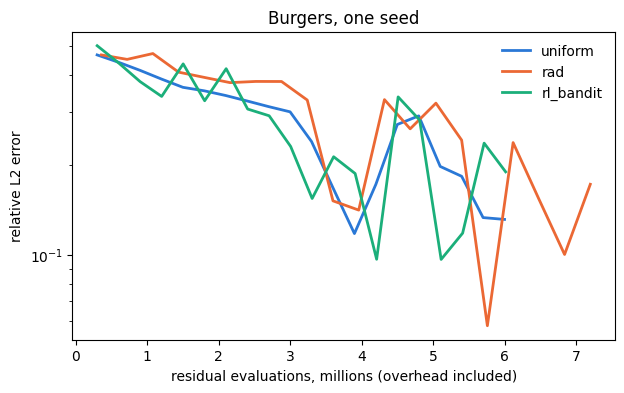

In [3]:
colors = {"uniform": "#2a78d6", "rad": "#eb6834", "rl_bandit": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 4))
for name, run in runs.items():
    ax.plot(np.array(run.curve_evals) / 1e6, run.curve_rel_l2, lw=2, color=colors[name], label=name)
ax.set_yscale("log")
ax.set_xlabel("residual evaluations, millions (overhead included)")
ax.set_ylabel("relative L2 error")
ax.set_title("Burgers, one seed")
ax.legend(frameon=False)
plt.show()

One seed is an anecdote: seed-to-seed variation on Burgers is as large as the differences between samplers. That
is why the claim comes from B01 (section 3), not from this plot.

## 2  Where do the points go?

Train one network briefly with uniform points, then ask each sampler for 2,000 points from that same network. The
background shows the network's current `|residual|`.

In [4]:
from pinnrl.config import Config, ModelConfig, TrainingConfig
from pinnrl.neural_networks import PINNModel
from pinnrl.pdes import BurgersEquation, PDEConfig
from pinnrl.rl.bandit_sampler import ResidualBanditSampler
from pinnrl.training import PDETrainer

device = torch.device("cpu")
training = TrainingConfig.from_dict({
    "batch_size": 1000,
    "num_collocation_points": 1000,
    "optimizer_config": {"learning_rate": 1e-3, "weight_decay": 0.0},
    "scheduler_type": "constant",
    "early_stopping": {"enabled": False},
})
pde = BurgersEquation(PDEConfig(
    name="Burgers Equation",
    domain=[[-1.0, 1.0]],
    time_domain=[0.0, 1.0],
    parameters={"nu": 0.01 / np.pi},
    boundary_conditions={"dirichlet": {"value": 0.0}},
    initial_condition={"type": "sine", "amplitude": -1.0, "frequency": 1.0},
    exact_solution={},
    dimension=1,
    device=device,
    training=training,
))
config = Config()
config.device, config.training = device, training
config.model = ModelConfig.from_architecture(
    "feedforward", {"hidden_dims": [64, 64, 64, 64], "activation": "tanh"}, input_dim=2, output_dim=1
)
model = PINNModel(config, device=device)
PDETrainer(model, pde, config=config, device=device).train_steps(num_steps=3000)

2026-10-23 19:05:47,569 - INFO - Adaptive weights are disabled


{'steps': 3000,
 'train_time_s': 16.31709784791019,
 'loss': [0.5740224719047546,
  0.5291209816932678,
  0.4952710270881653,
  0.4691605567932129,
  0.4500202536582947,
  0.4385504126548767,
  0.4358534812927246,
  0.4404720067977905,
  0.4460592269897461,
  0.44647759199142456,
  0.4419780671596527,
  0.43543773889541626,
  0.43011099100112915,
  0.427424818277359,
  0.4273926317691803,
  0.4287765324115753,
  0.4300479292869568,
  0.42988941073417664,
  0.42802539467811584,
  0.424895316362381,
  0.4214465916156769,
  0.4186914563179016,
  0.4173172116279602,
  0.4171181917190552,
  0.4171719551086426,
  0.4166089594364166,
  0.4143857955932617,
  0.4115597605705261,
  0.40891462564468384,
  0.40729981660842896,
  0.4066354036331177,
  0.40589502453804016,
  0.4043296277523041,
  0.4016121029853821,
  0.39871102571487427,
  0.39646780490875244,
  0.3950500786304474,
  0.39336729049682617,
  0.390353262424469,
  0.3870384693145752,
  0.3840932548046112,
  0.38187602162361145,
  0.378

In [5]:
n = 2000
x_u, t_u = pde.generate_collocation_points(n, strategy="uniform")
x_rad, t_rad = pde.generate_collocation_points(
    n, strategy="residual_based", model=model, k=1.0, c=1.0, pool_factor=20
)
bandit = ResidualBanditSampler((-1.0, 1.0), (0.0, 1.0))
for _ in range(200):  # let the bandit learn this network's residual map
    state = bandit.probe(pde, model, progress=0.5)
x_rl, t_rl = bandit.sample(pde, model, n, progress=0.5)

# |residual| of the current network on a grid, for the background
xg, tg = torch.meshgrid(torch.linspace(-1, 1, 200), torch.linspace(0, 1, 100), indexing="ij")
res = pde.compute_residual(model, xg.reshape(-1, 1), tg.reshape(-1, 1)).abs().detach().reshape(200, 100)

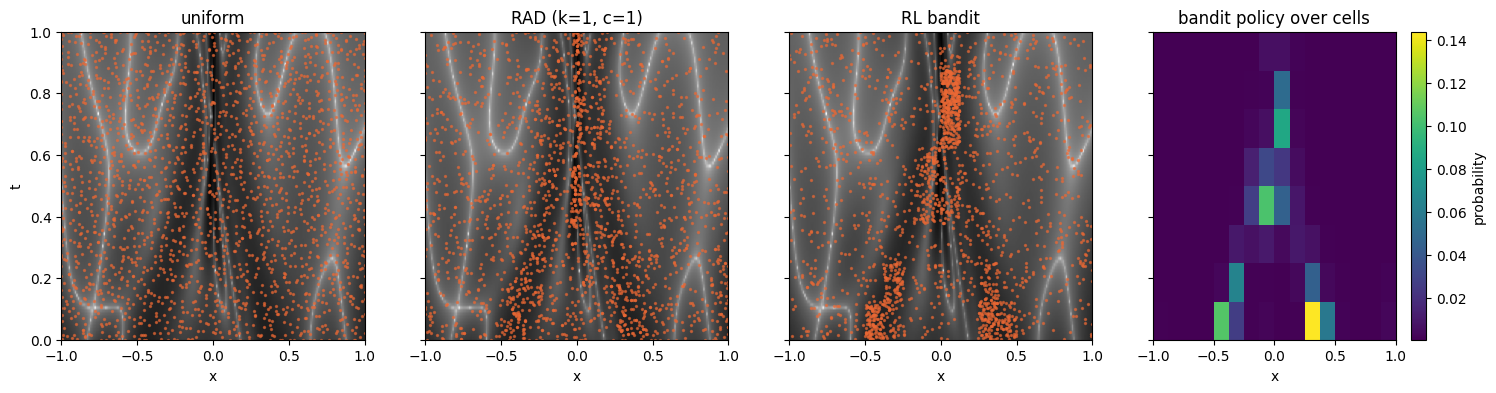

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
panels = [("uniform", x_u, t_u), ("RAD (k=1, c=1)", x_rad, t_rad), ("RL bandit", x_rl, t_rl)]
for ax, (title, x, t) in zip(axes, panels):
    ax.imshow(res.T.log10(), origin="lower", extent=(-1, 1, 0, 1), aspect="auto", cmap="Greys")
    ax.scatter(x.numpy(), t.numpy(), s=2, color="#eb6834", alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel("x")
axes[0].set_ylabel("t")
probs = bandit.distribution(state).reshape(bandit.n_x_cells, bandit.n_t_cells).detach()
im = axes[3].imshow(probs.T, origin="lower", extent=(-1, 1, 0, 1), aspect="auto", cmap="viridis")
axes[3].set_title("bandit policy over cells")
axes[3].set_xlabel("x")
fig.colorbar(im, ax=axes[3], label="probability")
plt.show()

## 3  What the multi-seed benchmark says (B01)

The same comparison over **10 paired seeds**, 15,000 steps, with stratified sampling and a "uniform every 100 steps"
control added (`pinnrl-benchmark sampling --seeds 10`). Median relative L2 error:

| PDE | uniform | stratified | uniform, every 100 | RAD | RL bandit |
|---|---|---|---|---|---|
| Burgers | 0.055 | 0.038 | 0.109 | 0.137 | 0.103 |
| Allen–Cahn | 0.568 | 0.564 | 0.570 | **0.533** (10/10 seeds) | **0.522** (10/10 seeds) |

- **Burgers:** no sampler is significantly better than uniform. Seed-to-seed variation (6×) and Adam's noise at a
  constant learning rate swamp the sampling effect. Once its probes count against the budget, the bandit is
  significantly worse (p = 0.03).
- **Allen–Cahn:** both adaptive samplers win on every seed (p = 0.002), but every method stays near the wrong
  solution (relative error > 0.5). The failure mode, not the sampler, is the bottleneck.

So: use uniform or stratified by default; try RAD for sharp features and compare at equal budget; treat the RL bandit as
experimental. Full write-up: `experiments/B01_sampling_equal_compute/README.md`.
